In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay

In [2]:
sns.set_style('whitegrid')
SEED = 42
np.random.seed(SEED)

In [3]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("gabrielsantello/advertisement-click-on-ad")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'advertisement-click-on-ad' dataset.
Path to dataset files: /kaggle/input/advertisement-click-on-ad


In [4]:
os.listdir(path)

['advertising.csv']

In [5]:
df = pd.read_csv(os.path.join(path, 'advertising.csv'))

In [6]:
num_cols = df.select_dtypes(include='number').columns.to_list()
cat_cols = df.select_dtypes(exclude='number').columns.to_list()

In [7]:
df.columns = df.columns.str.lower().str.replace(' ','_')

# Exploratory Data Analysis

In [8]:
df.head()

,daily_time_spent_on_site,age,area_income,daily_internet_usage,ad_topic_line,city,male,country,timestamp,clicked_on_ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,2016-03-27 00:53:11,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,2016-04-04 01:39:02,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,2016-03-13 20:35:42,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,2016-01-10 02:31:19,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,2016-06-03 03:36:18,0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   daily_time_spent_on_site  1000 non-null   float64
 1   age                       1000 non-null   int64  
 2   area_income               1000 non-null   float64
 3   daily_internet_usage      1000 non-null   float64
 4   ad_topic_line             1000 non-null   object 
 5   city                      1000 non-null   object 
 6   male                      1000 non-null   int64  
 7   country                   1000 non-null   object 
 8   timestamp                 1000 non-null   object 
 9   clicked_on_ad             1000 non-null   int64  
dtypes: float64(3), int64(3), object(4)
memory usage: 78.3+ KB


In [10]:
df.describe()

,daily_time_spent_on_site,age,area_income,daily_internet_usage,male,clicked_on_ad
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,65.000200,36.009000,55000.000080,180.000100,0.481000,0.50000
std,15.853615,8.785562,13414.634022,43.902339,0.499889,0.50025
min,32.600000,19.000000,13996.500000,104.780000,0.000000,0.00000
25%,51.360000,29.000000,47031.802500,138.830000,0.000000,0.00000
50%,68.215000,35.000000,57012.300000,183.130000,0.000000,0.50000
75%,78.547500,42.000000,65470.635000,218.792500,1.000000,1.00000
max,91.430000,61.000000,79484.800000,269.960000,1.000000,1.00000


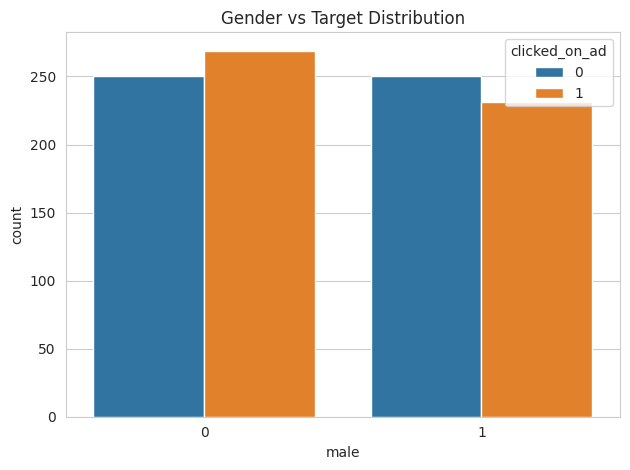

In [11]:
num_feat = ['daily_time_spent_on_site', 'age', 'area_income', 'daily_internet_usage']
sns.countplot(data=df, x='male', hue='clicked_on_ad');
plt.title('Gender vs Target Distribution')
plt.tight_layout()

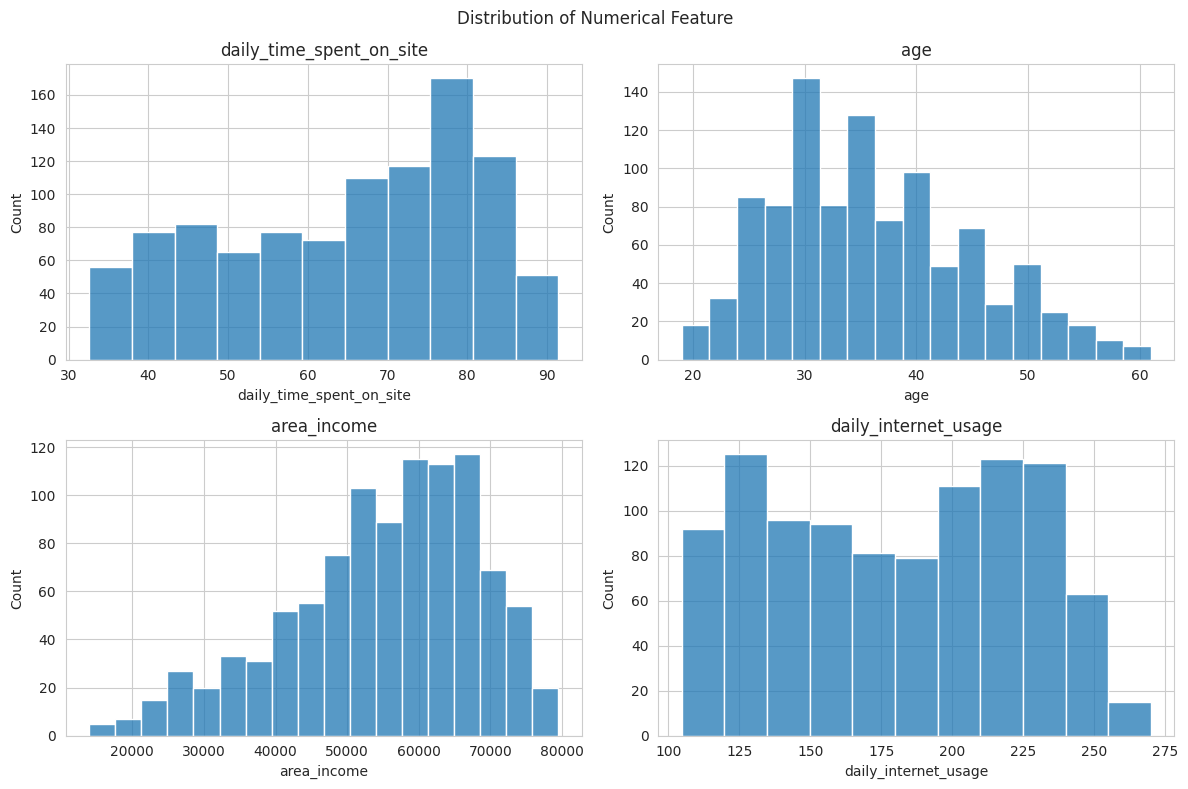

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12,8))
for feature, ax in zip(num_feat, axes.flatten()):
    sns.histplot(x=df[feature], ax=ax)
    ax.set_title(feature)
plt.suptitle('Distribution of Numerical Feature')
plt.tight_layout()
plt.show()

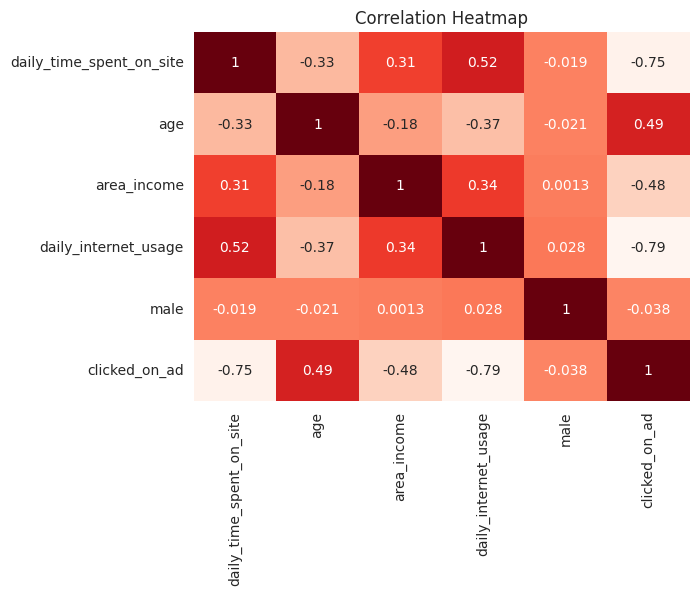

In [13]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cbar=False, cmap='Reds')
plt.title('Correlation Heatmap')
plt.show()

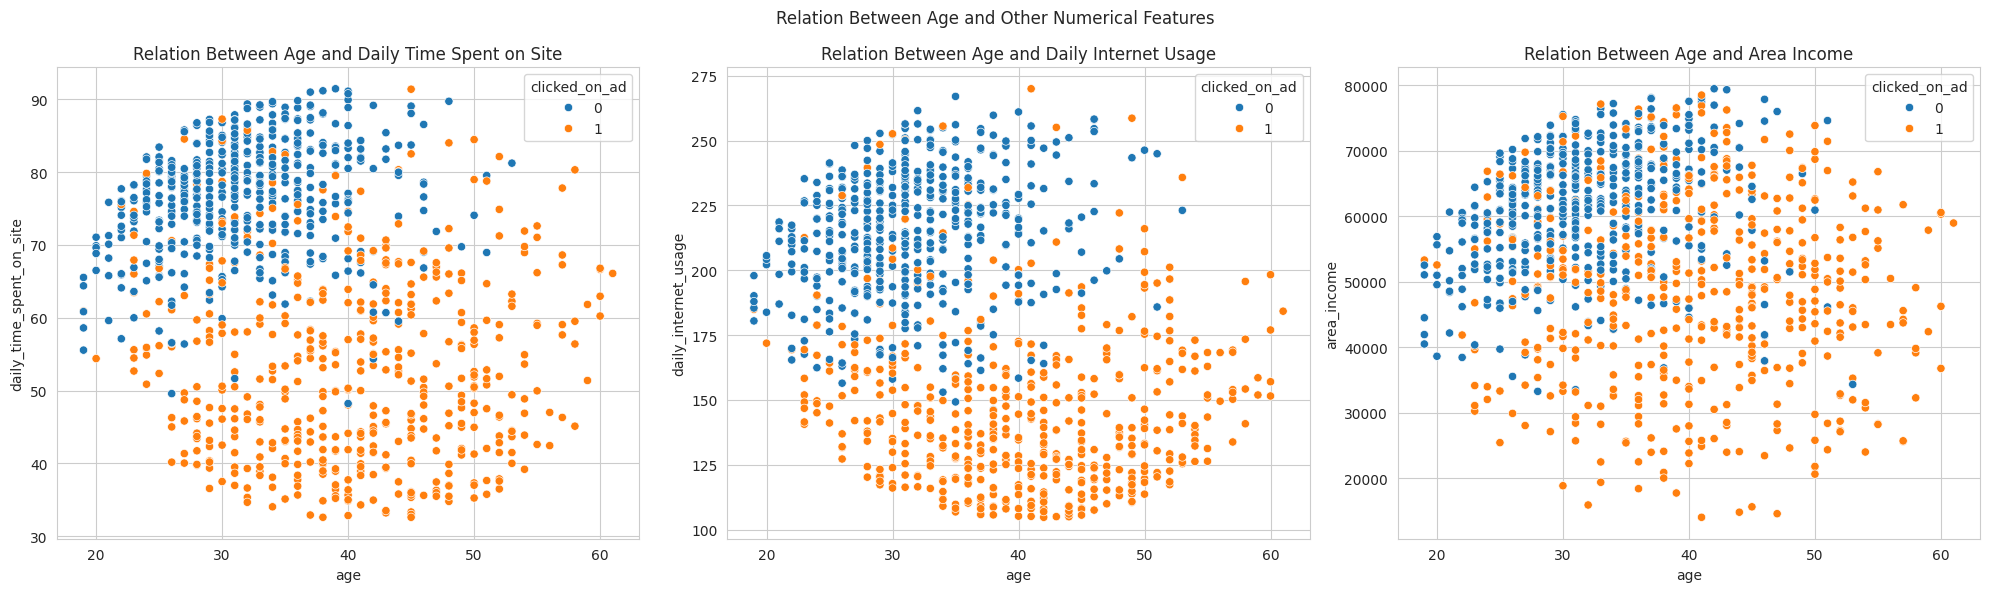

In [14]:
fig, axes = plt.subplots(1,3,figsize=(20,6))
sns.scatterplot(x='age', y='daily_time_spent_on_site', data=df, hue='clicked_on_ad', ax=axes[0])
axes[0].set_title('Relation Between Age and Daily Time Spent on Site')

sns.scatterplot(x='age', y='daily_internet_usage', data=df, hue='clicked_on_ad', ax=axes[1])
axes[1].set_title('Relation Between Age and Daily Internet Usage')

sns.scatterplot(x='age', y='area_income', data=df, hue='clicked_on_ad', ax=axes[2])
axes[2].set_title('Relation Between Age and Area Income')

plt.suptitle('Relation Between Age and Other Numerical Features')
plt.tight_layout()
plt.show()

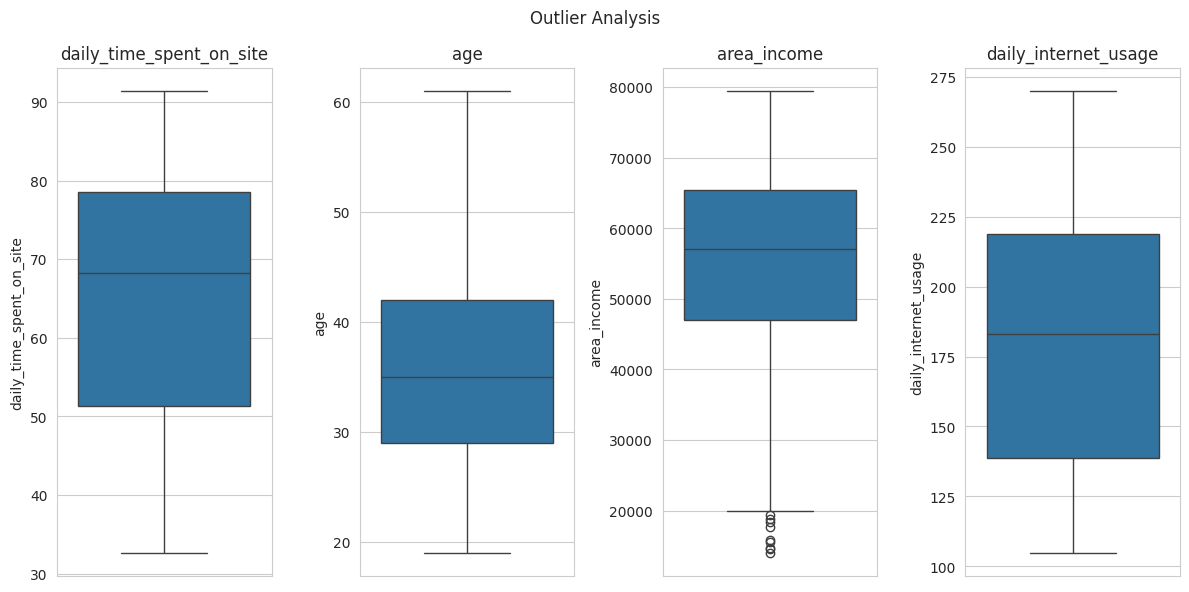

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(12,6))
for feature, ax in zip(num_feat, axes.flatten()):
    sns.boxplot(y=df[feature], ax=ax)
    ax.set_title(feature)
plt.suptitle('Outlier Analysis')
plt.tight_layout()
plt.show()

# Data Preprocessing

Train Test Split

In [16]:
X = df.drop(['ad_topic_line', 'city', 'country', 'timestamp', 'clicked_on_ad'], axis=1)
y = df['clicked_on_ad']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((800, 5), (200, 5), (800,), (200,))

In [17]:
X_train.head()

,daily_time_spent_on_site,age,area_income,daily_internet_usage,male
29,76.02,22,46179.97,209.82,0
535,78.76,32,70012.83,208.02,1
695,73.49,38,67132.46,244.23,0
557,79.67,28,58576.12,226.79,0
836,49.21,46,49206.40,115.60,0


In [18]:
X_test.head()

,daily_time_spent_on_site,age,area_income,daily_internet_usage,male
521,63.26,29,54787.37,120.46,1
737,71.23,52,41521.28,122.59,0
740,43.63,38,61757.12,135.25,1
660,42.04,49,67323.00,182.11,0
411,78.68,29,66225.72,208.05,0


Feature Scaling

In [19]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [20]:
X_train

array([[ 0.68151885, -1.59171433, -0.6639286 ,  0.64565463, -0.95596841],
       [ 0.85377694, -0.45872077,  1.11780512,  0.60455583,  1.04605967],
       [ 0.52246303,  0.22107537,  0.90246998,  1.43132657, -0.95596841],
       ...,
       [ 1.64654135,  1.01417086, -0.23476995,  0.02529117,  1.04605967],
       [-0.53560399,  0.67427279,  1.31753347, -0.96176486, -0.95596841],
       [ 1.5547542 ,  0.44767408,  0.33886526,  0.28969341, -0.95596841]])

In [21]:
X_test

array([[-0.12067575, -0.79861884, -0.02044331, -1.39467215,  1.04605967],
       [ 0.38038154,  1.80726636, -1.01221014, -1.34603858, -0.95596841],
       [-1.35477293,  0.22107537,  0.50061201, -1.05697706,  1.04605967],
       [-1.45473292,  1.46736829,  0.91671466,  0.01296153, -0.95596841],
       [ 0.84874751, -0.79861884,  0.83468251,  0.60524081, -0.95596841],
       [ 1.42524629, -0.23212206, -0.24256139, -0.65146897, -0.95596841],
       [ 1.29448103, -1.02521755, -0.209259  ,  0.23375338,  1.04605967],
       [-0.38032024,  0.90087151, -0.41382803, -1.72391915,  1.04605967],
       [ 1.13102445,  0.78757215, -0.06048378,  1.43520812,  1.04605967],
       [-1.68545817, -0.00552334, -1.0340489 , -0.93801889, -0.95596841],
       [ 0.92481769, -0.68531948, -0.35172602,  1.36625348,  1.04605967],
       [-0.96624921, -0.1188227 ,  0.14570155, -1.40380522,  1.04605967],
       [-0.36586062,  1.46736829, -0.6077797 , -1.61432237, -0.95596841],
       [ 0.98642824, -0.91191819,  0.6

# Modeling

In [ ]:
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

# Evaluation

In [26]:
print('Train Score',model.score(X_train, y_train))
print('Test Score',model.score(X_test, y_test))

Train Score 0.97625
Test Score 0.96


In [27]:
y_pred = model.predict(X_test)

In [28]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.97      0.96        89
           1       0.97      0.95      0.96       111

    accuracy                           0.96       200
   macro avg       0.96      0.96      0.96       200
weighted avg       0.96      0.96      0.96       200



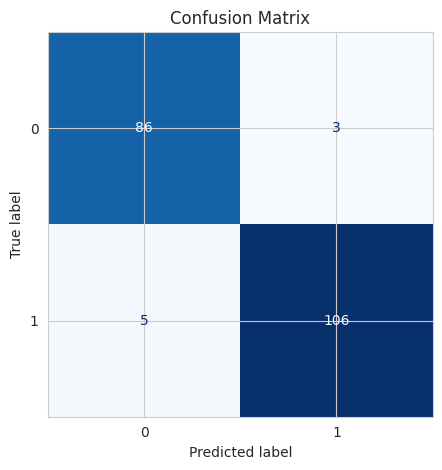

In [32]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, colorbar=False, cmap='Blues')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

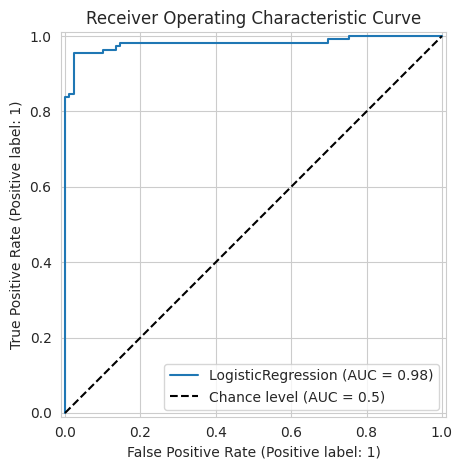

In [36]:
RocCurveDisplay.from_estimator(model, X_test, y_test, plot_chance_level=True)
plt.title('Receiver Operating Characteristic Curve')
plt.tight_layout()
plt.show()